In [26]:
import pandas as pd
import numpy as np
import datetime

# Recency Frequency Monetary(RFM) Analysis 

The purpose of this section of the project is to perfom the Recency Frequency Monetary analysis on the cleaned E-Commerce csv file from the previous section.
The main steps taken 

- Check the data types quality issues in the dataframe.
- check for missing values.
- Set a reference date to perfom the Recency Frequency Monetary analysis. 
- Group the dataframe by Customer_Id, and perfom aggregations for recency,frequency and monetary using the order_date, order_id and gross sales.
- Calculate Recency Frequency Monetary Scores (Scale of 1-5 using 5 bins discretization).
- Classify or Segement the customers as **( Champions, Loyal Customers, Potenctial Loyalists, New Customers, At Risk, Lost and Others )** based on the RFM Scores.
- Save the final result as csv file for dashboard development in PoweBI.
- Sketch countplots of the customer segments using Seaborn and matplotlib.pyplot to gain insights on the customer segments distributions. 

In [27]:
data = pd.read_csv('Cleaned_E_Commerce.csv',date_format='%Y-%m-%d')

In [28]:
data.head()

,order_id,order_date,order_time,order_status,sales_channel,customer_id,customer_name,customer_age,gender,customer_segment,...,discount_amount,tax_amount,shipping_cost,net_sales,product_cost,profit,profit_margin_percentage,customer_lifetime_value,is_repeat_customer,customer_order_count
0,ORD-301242,2023-11-06,16:37:47,Completed,Mobile App,CUST-003102,Jasmine Ryan,55,Male,Consumer,...,477.89,61.07,12.03,945.40,588.33,345.04,36.50,12459.68,True,11
1,ORD-773460,2025-12-24,01:22:36,Completed,Website,CUST-003124,Scott Chase,26,Male,Premium,...,1456.06,320.83,9.00,2018.41,2031.88,-22.47,-1.11,13032.48,True,11
2,ORD-449374,2021-07-05,14:24:21,Completed,Mobile App,CUST-012496,Marc Wheeler,69,Female,Premium,...,97.30,29.79,13.05,468.35,257.73,197.57,42.18,6159.44,True,6
3,ORD-567636,2023-01-21,07:20:26,Completed,Social Media,CUST-023928,Jennifer Smith,65,Male,Consumer,...,53.34,34.39,20.85,546.52,277.84,247.83,45.35,5638.30,True,7
4,ORD-820028,2022-05-13,09:46:21,Completed,Social Media,CUST-012730,Jessica Wang,34,Female,Consumer,...,133.63,421.35,23.03,2785.27,1231.88,1530.36,54.94,13240.10,True,8


### Checking data type of the dataframe columns

In [29]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 138116 entries, 0 to 138115
Data columns (total 46 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   order_id                  138116 non-null  str    
 1   order_date                138116 non-null  str    
 2   order_time                138116 non-null  str    
 3   order_status              138116 non-null  str    
 4   sales_channel             138116 non-null  str    
 5   customer_id               138116 non-null  str    
 6   customer_name             138116 non-null  str    
 7   customer_age              138116 non-null  int64  
 8   gender                    138116 non-null  str    
 9   customer_segment          138116 non-null  str    
 10  customer_type             138116 non-null  str    
 11  customer_city             138116 non-null  str    
 12  customer_state            138116 non-null  str    
 13  customer_country          138116 non-null  str    
 14 

### Change the order_date data type from string to datetime

In [30]:
data['order_date'] = pd.to_datetime(rfm['order_date'],format = '%Y-%m-%d')

### Checking for missing values in the dataframe

In [31]:
data.isnull().sum()

order_id                    0
order_date                  0
order_time                  0
order_status                0
sales_channel               0
customer_id                 0
customer_name               0
customer_age                0
gender                      0
customer_segment            0
customer_type               0
customer_city               0
customer_state              0
customer_country            0
region                      0
customer_postal_code        0
payment_method              0
payment_status              0
currency                    0
shipping_method             0
warehouse                   0
delivery_days               0
estimated_delivery_days     0
delivery_status             0
return_status               0
return_reason               0
customer_rating             0
review_sentiment            0
customer_review             0
marketing_channel           0
campaign_name               0
coupon_code                 0
loyalty_points_earned       0
loyalty_po

### Check for dupplicated rows of records

In [32]:
data[data.duplicated()]

,order_id,order_date,order_time,order_status,sales_channel,customer_id,customer_name,customer_age,gender,customer_segment,...,discount_amount,tax_amount,shipping_cost,net_sales,product_cost,profit,profit_margin_percentage,customer_lifetime_value,is_repeat_customer,customer_order_count


### Define the recency frequency monetary dataframe

In [33]:
rfm = data[['order_id','order_date','customer_id','gross_sales']]

In [34]:
rfm.head()

,order_id,order_date,customer_id,gross_sales
0,ORD-301242,2023-11-06,CUST-003102,1350.19
1,ORD-773460,2025-12-24,CUST-003124,3144.64
2,ORD-449374,2021-07-05,CUST-012496,522.81
3,ORD-567636,2023-01-21,CUST-023928,544.62
4,ORD-820028,2022-05-13,CUST-012730,2474.52


### Explore the oldest and most recent orderdate

In [35]:
oldest, youngest = rfm['order_date'].min(), rfm['order_date'].max() 


In [36]:
print(' The oldest orderdate was placed on: {} \n\n The most recent orderdate was placed on: {}'.format(oldest.date(),youngest.date()))

 The oldest orderdate was placed on: 2021-01-01 

 The most recent orderdate was placed on: 2025-12-31


### Define the RFM Analysis reference date as: one day from the most recent order

In [37]:
reference_date = rfm['order_date'].max() + pd.Timedelta(days = 1)  # RFM Analysis reference date: one day from the most recent order

In [38]:
print(f'The RFM Analysis reference date is: {reference_date.date()}')

The RFM Analysis reference date is: 2026-01-01


### Recency Frequency Monetary aggregations

In [39]:
rfm['order_id'].nunique()

138116

- The dataset cointains unique order_id's, 
- Which means we will use either count() or nunique() to aggregate the number of orders per customer_id.

In [40]:
rfm = rfm.groupby('customer_id').agg({
    'order_date':lambda x:(reference_date - x.max()).days,
    'order_id': 'nunique',    # number of orders per customer_id.
    'gross_sales': 'sum'      # Total sales per customer_id
}).reset_index()

In [41]:
rfm.head()

,customer_id,order_date,order_id,gross_sales
0,CUST-000001,7,9,10260.22
1,CUST-000002,283,10,16602.49
2,CUST-000003,210,7,7244.70
3,CUST-000004,55,7,14330.31
4,CUST-000005,413,8,12375.10


In [42]:
rfm = rfm.rename({'customer_id':'Customer_Id','order_date':'Recency', 'order_id':'Frequency', 'gross_sales':'Monetary'},axis=1)

In [43]:
rfm.head()

,Customer_Id,Recency,Frequency,Monetary
0,CUST-000001,7,9,10260.22
1,CUST-000002,283,10,16602.49
2,CUST-000003,210,7,7244.70
3,CUST-000004,55,7,14330.31
4,CUST-000005,413,8,12375.10


### Calculate RFM Scores (Scale of 1-5 using 5 bins discretization)

**For Recency, smaller numbers are better (more recent), so labels are reversed) [5, 4, 3, 2, 1]**

In [44]:
rfm['R_Score'] = pd.cut(x = rfm['Recency'], bins = 5, labels = [5,4,3,2,1], duplicates='drop')

**For Frequency and Monetary, larger numbers are better, so labels are in ascending [1,2,3,4,5]**

In [45]:
rfm['F_Score'] = pd.cut(x = rfm['Frequency'], bins = 5, labels = [1,2,3,4,5], duplicates='drop')
rfm['M_Score'] = pd.cut(x = rfm['Monetary'], bins = 5, labels = [1,2,3,4,5], duplicates='drop')

**Concatenate scores to find the target customer segment string**

In [46]:
 rfm['RFM_Score'] = rfm['R_Score'].astype(str)+rfm['F_Score'].astype(str)+rfm['M_Score'].astype(str)

In [47]:
rfm.head()

,Customer_Id,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
0,CUST-000001,7,9,10260.22,5,3,2,532
1,CUST-000002,283,10,16602.49,5,3,3,533
2,CUST-000003,210,7,7244.70,5,2,2,522
3,CUST-000004,55,7,14330.31,5,2,3,523
4,CUST-000005,413,8,12375.10,4,2,2,422


## Customer Segmentation

**Define the customer segmentation function**

In [48]:
def customer_segmentation(r,f,m):
    
        # Best in all three metrics
        if r >= 4 and f >= 4 and m >= 4:
            return "Champions"
            
         #  Above average in all metrics 
        elif r >= 3 and f >= 3 and m >= 3:
            return "Loyal Customers"

        # Needs to improve one metric towards average 
        elif (r >= 3 and f >= 3 and m == 2) or (r >= 3 and f == 2 and m >= 3) or (r == 2 and f >= 3 and m >= 3):
            return "Potential Loyal"
            
        # Below average in recency and frequency, but fairly good to best monetarily
        elif (2 <=r <  3) and (2 <= f < 3) and (2 <= m <= 5):
            return "At Risk"

        # Recently purchased, but not as frequent.
        elif r>=4 and f==2 and m<=2 :
            return "New Customers"

        # Have not purchased in a long time.
        elif r==1 and f==1:
            return "Lost"

        # Poor in one of the three metrics
        else:
            return 'Others'

**Apply the function to the RFM Dataframe**       

In [49]:
rfm['Customer_Segment'] = rfm[['R_Score','F_Score','M_Score']].apply(lambda row: customer_segmentation(row['R_Score'],row['F_Score'],row['M_Score']),axis = 1)

**Check the values counts of the segments**

In [50]:
rfm['Customer_Segment'].value_counts()

Customer_Segment
New Customers      11942
Others              9212
Potential Loyal     2474
Loyal Customers     1016
Lost                 176
Champions             53
At Risk               38
Name: count, dtype: int64

### Save the rfm DataFrame as (RFM_E_Commerce.csv) for Further Vitualization in PowerBI

In [51]:
rfm.to_csv('RFM_E_Commerce.csv',index = False)

In [52]:
pd.read_csv('RFM_E_Commerce.csv').head()

,Customer_Id,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Customer_Segment
0,CUST-000001,7,9,10260.22,5,3,2,532,Potential Loyal
1,CUST-000002,283,10,16602.49,5,3,3,533,Loyal Customers
2,CUST-000003,210,7,7244.70,5,2,2,522,New Customers
3,CUST-000004,55,7,14330.31,5,2,3,523,Potential Loyal
4,CUST-000005,413,8,12375.10,4,2,2,422,New Customers


### Sketch countplots of the customer segments using Seaborn and matplotlib.pyplot to gain insights on the customer segments distributions.

In [53]:
import matplotlib.pyplot as plt
import seaborn as sns

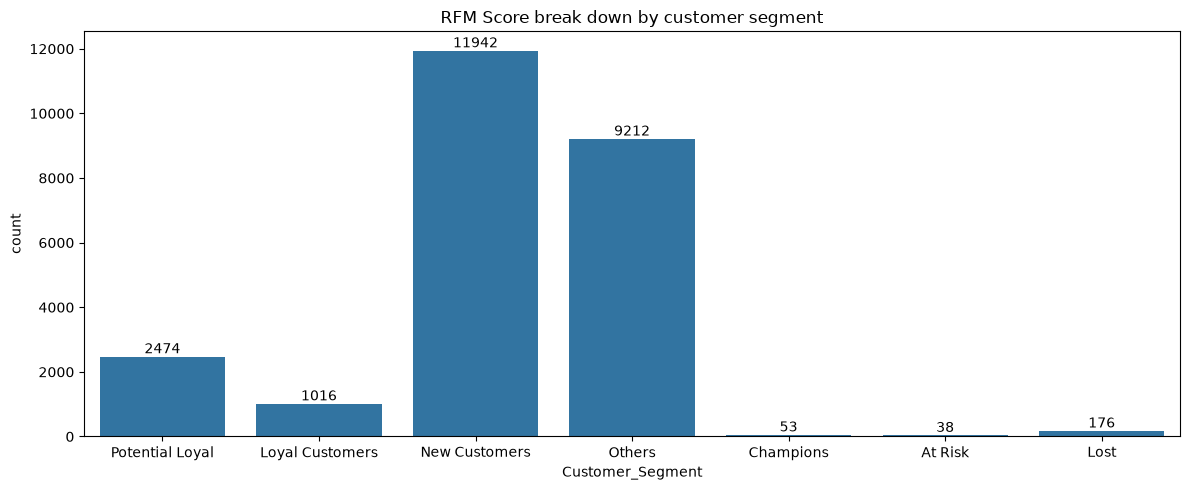

In [54]:
plt.figure(figsize = (12,5))
ax = sns.countplot(x = 'Customer_Segment',data = rfm)
ax.bar_label(ax.containers[0])
plt.title('RFM Score break down by customer segment')
plt.tight_layout()

Text(0.5, 1.0, 'Others')

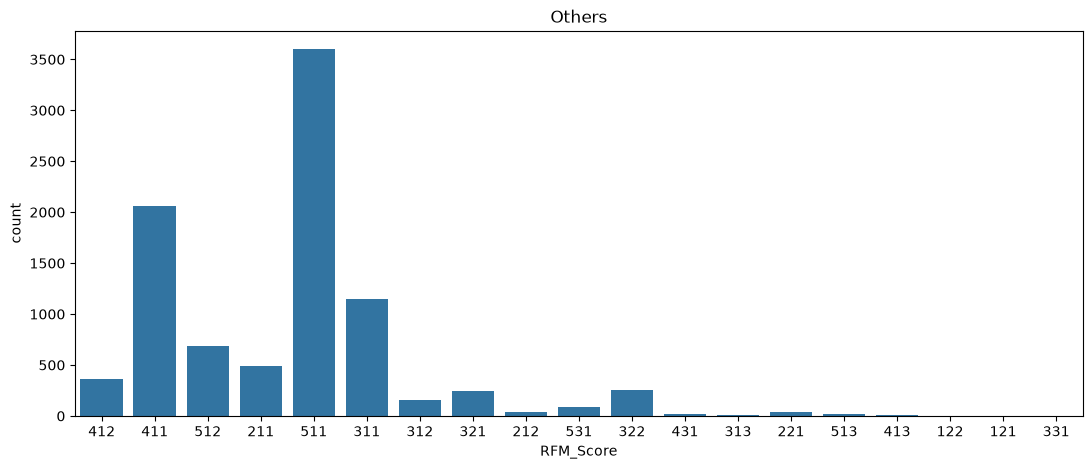

In [55]:
plt.figure(figsize = (13,5))
sns.countplot(x = 'RFM_Score',data = rfm[rfm['Customer_Segment']=='Others'])
plt.title('Others')

Text(0.5, 1.0, 'Champions')

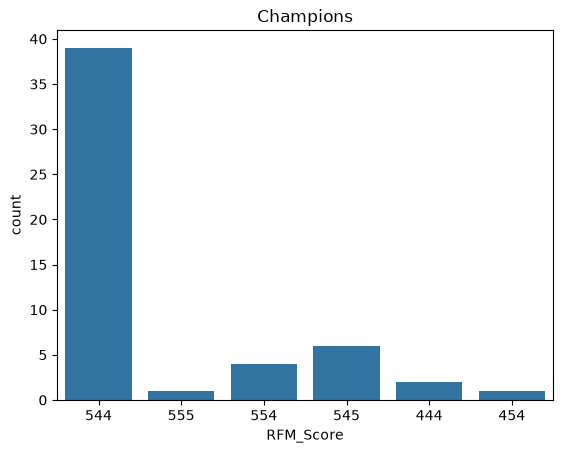

In [56]:
sns.countplot(x = 'RFM_Score',data = rfm[rfm['Customer_Segment']=='Champions'])
plt.title('Champions')

Text(0.5, 1.0, 'Loyal Customers')

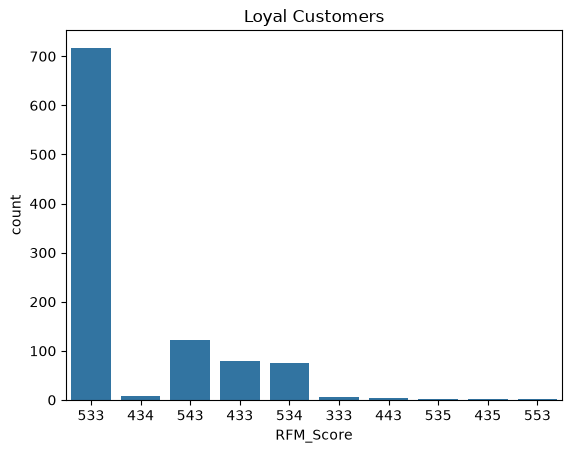

In [57]:
sns.countplot(x = 'RFM_Score',data = rfm[rfm['Customer_Segment']=='Loyal Customers'])
plt.title('Loyal Customers')

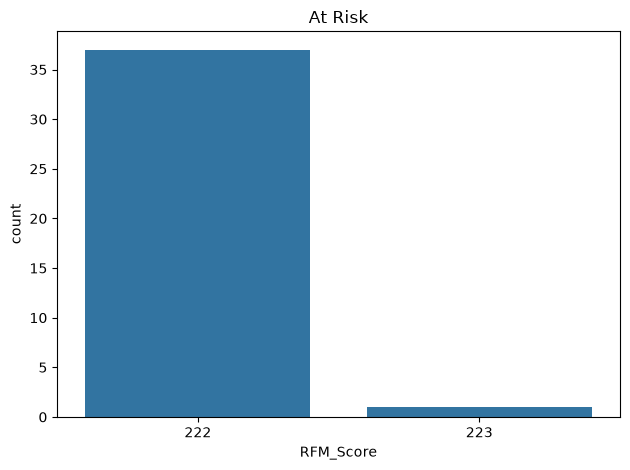

In [58]:

sns.countplot(x = 'RFM_Score',data = rfm[rfm['Customer_Segment']=='At Risk'])
plt.title('At Risk')
plt.tight_layout()

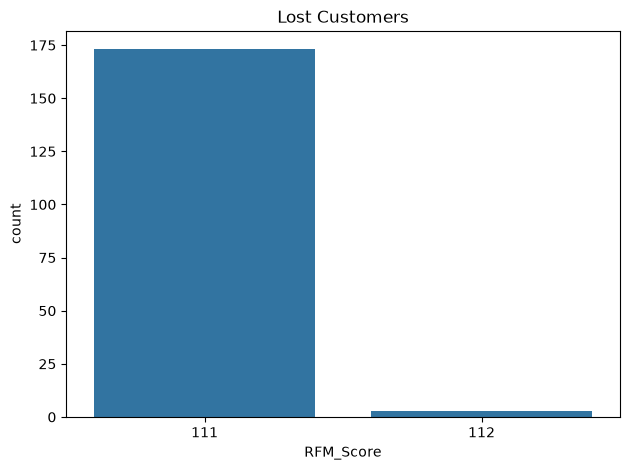

In [59]:
sns.countplot(x = 'RFM_Score',data = rfm[rfm['Customer_Segment']=='Lost'])
plt.title('Lost Customers')
plt.tight_layout()

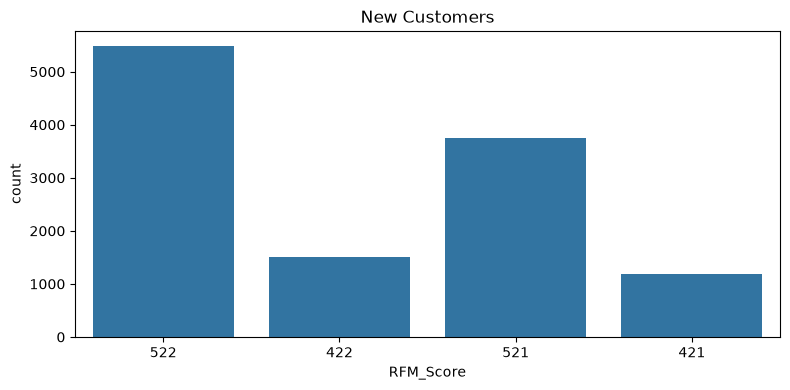

In [60]:
plt.figure(figsize=(8,4))
sns.countplot(x = 'RFM_Score',data = rfm[rfm['Customer_Segment']=='New Customers'])
plt.title('New Customers')
plt.tight_layout()

Text(0.5, 1.0, 'Potential Loyalists')

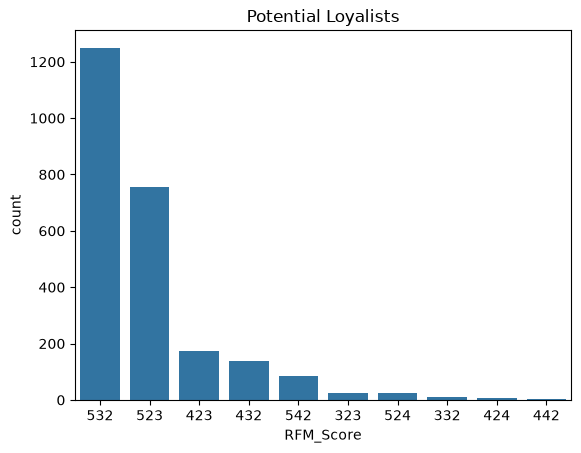

In [61]:
sns.countplot(x = 'RFM_Score',data = rfm[rfm['Customer_Segment']=="Potential Loyal"])
plt.title("Potential Loyalists")